In [1]:
import numpy as np

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

In [5]:
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])

In [6]:
df.head()

,Feature 1,Feature 2
0,0.836857,2.136359
1,-1.413658,7.409623
2,1.155213,5.099619
3,-1.018616,7.814915
4,1.271351,1.892542


In [7]:
scaler = StandardScaler()

In [8]:
X_scaled = scaler.fit_transform(X)

In [9]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

In [10]:
wcss

[600.0000000000001,
 270.3431137506443,
 139.34634510769777,
 56.02477057509952,
 48.60211490891997,
 41.797146136796435,
 35.22161787598449,
 29.452441405736934,
 27.417236930918243,
 25.231797277512396]

Text(0, 0.5, 'WCSS')

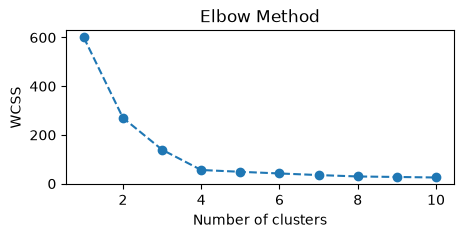

In [12]:
plt.figure(figsize=(5, 2))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')


In [13]:
cluster_labels = KMeans(n_clusters=4, init='k-means++', max_iter=300, n_init=10, random_state=0).fit_predict(X_scaled)
cluster_labels

array([2, 3, 0, 3, 2, 2, 1, 0, 3, 3, 1, 3, 0, 3, 2, 0, 0, 2, 1, 1, 2, 2,
       0, 1, 1, 0, 2, 0, 1, 0, 3, 3, 0, 3, 3, 3, 3, 3, 1, 2, 0, 1, 0, 0,
       1, 1, 3, 1, 3, 2, 1, 2, 3, 2, 2, 1, 3, 1, 3, 2, 3, 0, 3, 1, 1, 1,
       3, 2, 3, 1, 0, 1, 3, 1, 1, 3, 1, 0, 2, 3, 2, 0, 2, 2, 3, 0, 2, 0,
       3, 3, 0, 2, 3, 1, 1, 0, 2, 2, 0, 1, 3, 2, 3, 2, 0, 2, 2, 0, 3, 0,
       1, 1, 2, 3, 2, 0, 3, 2, 2, 0, 1, 2, 1, 2, 2, 2, 2, 1, 2, 1, 3, 1,
       1, 2, 3, 1, 1, 3, 0, 3, 3, 1, 0, 1, 0, 1, 3, 0, 3, 3, 3, 0, 3, 0,
       2, 1, 3, 1, 2, 0, 3, 0, 0, 2, 0, 1, 1, 0, 2, 0, 0, 3, 2, 0, 1, 3,
       2, 2, 0, 1, 2, 0, 1, 1, 0, 0, 0, 0, 2, 3, 0, 1, 0, 0, 1, 1, 1, 0,
       1, 3, 0, 1, 2, 1, 0, 3, 1, 3, 0, 3, 0, 1, 0, 0, 3, 1, 1, 2, 2, 0,
       3, 2, 2, 1, 2, 1, 0, 3, 3, 0, 0, 3, 0, 2, 1, 0, 2, 1, 3, 1, 2, 0,
       2, 3, 3, 3, 3, 1, 1, 3, 0, 1, 2, 0, 1, 1, 1, 2, 2, 3, 0, 0, 1, 2,
       3, 1, 0, 3, 0, 2, 2, 1, 1, 0, 2, 2, 2, 0, 3, 3, 2, 2, 0, 2, 2, 2,
       3, 1, 3, 0, 2, 2, 3, 3, 3, 2, 2, 0, 3, 1], d

In [14]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

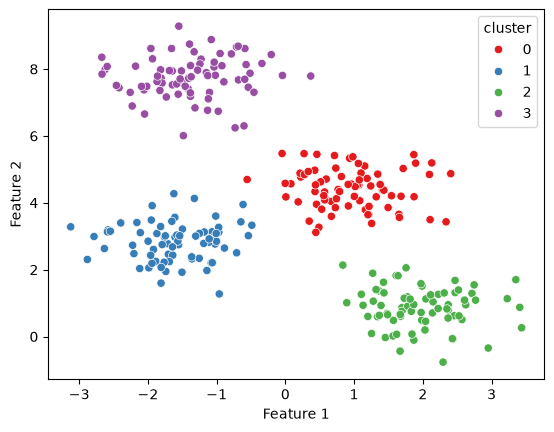

In [15]:
sns.scatterplot(data=df, x='Feature 1', y='Feature 2', hue='cluster', palette='Set1')

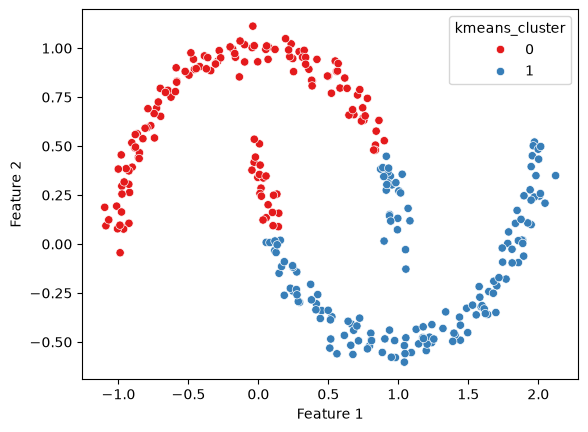

In [16]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=300, noise=0.05, random_state=0)
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
# standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
#kmeans and dbscan clustering
from sklearn.cluster import DBSCAN
kmeans = KMeans(n_clusters=2, random_state=0)
kmeans_labels = kmeans.fit_predict(X_scaled)
df['kmeans_cluster'] = kmeans_labels
sns.scatterplot(data=df, x='Feature 1', y='Feature 2', hue='kmeans_cluster', palette='Set1')
dbscan = DBSCAN(eps=0.1, min_samples=5)

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

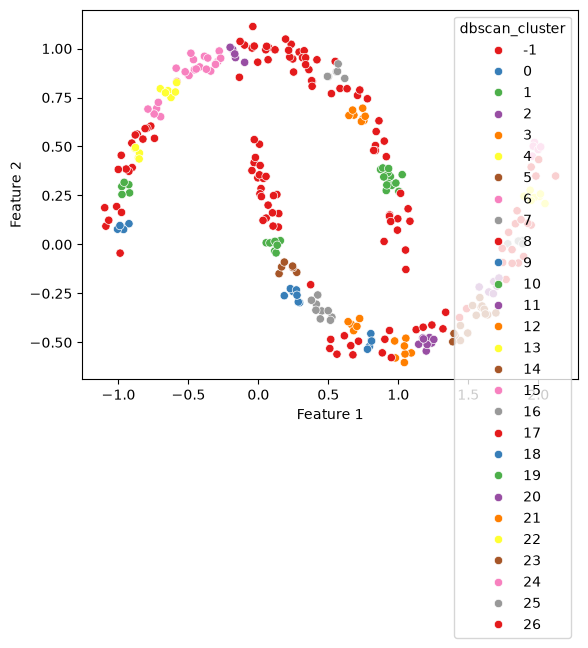

In [17]:
dbscan_labels = dbscan.fit_predict(X_scaled)
df['dbscan_cluster'] = dbscan_labels
sns.scatterplot(data=df, x='Feature 1', y='Feature 2', hue='dbscan_cluster', palette='Set1')